In [389]:
import torch
import torch.nn as nn
import torch.nn.functional as F

In [390]:
# Material Parameters
mu = 0.8 # Shear modulus - This tells us how the material behaves at the very beginning of a stretch.
jm = 40.0 # The Streching limit 
Identity = torch.eye(3) #Reference deformation gradient -  We assume the measurement uncertainty increases as the deformation increases moves away from the underformed reference configuration.

In [391]:
# Gent Stress Function
def gent_stress_function(lamda, mu, jm):
    I1 = lamda**2 + 2/lamda
    stress = mu * (lamda - 1/lamda**2) / (1 - (I1 - 3)/jm)
    return stress

In [392]:
# Since it is Isotropic and Uniaxial, lamda1*lamda2*lamda3 = 1, we can write the deformation gradient as a diagonal matrix with lamda, lamda^(-1/2), lamda^(-1/2) on the diagonal.
def deformation_gradient(lamda):
    diagonal_values = torch.stack([
        lamda,
        lamda**(-0.5),
        lamda**(-0.5)
    ], dim=-1) #dim 0 means that stack tensors along rows dim=-1 means that stack tensors along columns or last dimension.

    return torch.diag_embed(diagonal_values)

In [393]:
def frobenius_norm(F):
    return torch.sqrt(
        torch.sum((F - Identity)**2, dim=(-2, -1))
    )
# Frobenius norm is the overall magnitude of the matrix, square of all the terms.
# Here we are calculating the Frobenius norm of the difference between the deformation gradient and the identity matrix, which gives us a measure of how much the material has deformed from its original state.

In [394]:
def add_noise(P_true_train,eta_min,eta_max,lamda):
    P_char = torch.max(torch.abs(P_true_train))
    noise_sd_min = eta_min * P_char
    noise_sd_max = eta_max * P_char
    F = deformation_gradient(lamda)
    F_lambdamax = deformation_gradient(torch.max(lamda))
    q = 2.0
    t = frobenius_norm(F)
    ksy = torch.randn_like(P_true_train)
    conditional_noise_variance = torch.square(noise_sd_min) + (torch.square(noise_sd_max) - torch.square(noise_sd_min)) * ((t / frobenius_norm(F_lambdamax))**q)
    noise = torch.sqrt(conditional_noise_variance) * ksy
    return noise,conditional_noise_variance

In [395]:
# Synthetic Data Generation
def generate_synthetic_data(num_samples, lamda_min, lamda_max,eta_min,eta_max):
    lamda_train = torch.linspace(lamda_min, lamda_max, num_samples)
    I1_train = lamda_train**2 + 2/lamda_train
    P_true_train = gent_stress_function(lamda_train, mu, jm)   
    noise,conditional_noise_variance = add_noise(P_true_train,eta_min,eta_max,lamda_train)
    Y_train = P_true_train + noise
    Y_train = Y_train.reshape(-1, 1)
    lamda_train =lamda_train.reshape(-1, 1)
    I1_train = I1_train.reshape(-1, 1)
    x = torch.cat((lamda_train, I1_train,Y_train), dim=1)
    return x,conditional_noise_variance


In [396]:
x, conditional_noise_variance = generate_synthetic_data(num_samples=500, lamda_min=1.0, lamda_max=4.0, eta_min=0.005,eta_max=0.03)

In [397]:
def noise(u):
    return torch.log(u) - torch.log(1-u)

In [398]:
class NeuralNetwork(nn.Module):
    def __init__(self,m = 10):
        super().__init__()
        self.a = nn.Parameter(torch.randn(1))
        self.c = nn.Parameter(torch.randn(m))
        self.w = nn.Parameter(torch.randn(m))
        self.b = nn.Parameter(torch.randn(m))

        # Extreme Sparsification:
        self.beta = 2/3

        self.log_alpha_a = nn.Parameter(torch.randn(1))
        self.log_alpha_c = nn.Parameter(torch.randn(m))
        self.log_alpha_w = nn.Parameter(torch.randn(m))
        self.log_alpha_b = nn.Parameter(torch.randn(m))   

        self.gamma = -0.1
        self.zeta = 1.1  

    
    def forward(self,I1):
        u_a = torch.rand_like(self.a)
        u_c = torch.rand_like(self.c)
        u_w = torch.rand_like(self.w)
        u_b = torch.rand_like(self.b)

        eps = 1e-6

        u_a = torch.clamp(u_a, eps, 1-eps)
        u_c = torch.clamp(u_c, eps, 1-eps)
        u_w = torch.clamp(u_w, eps, 1-eps)
        u_b = torch.clamp(u_b, eps, 1-eps)

        s_a = torch.sigmoid((noise(u_a) + (self.log_alpha_a) )/self.beta)
        s_c = torch.sigmoid((noise(u_c) + (self.log_alpha_c) )/self.beta)
        s_w = torch.sigmoid((noise(u_w) + (self.log_alpha_w) )/self.beta)
        s_b = torch.sigmoid((noise(u_b) + (self.log_alpha_b) )/self.beta)

        s_bar_a = s_a*(self.zeta-self.gamma) +  self.gamma
        s_bar_c = s_c*(self.zeta-self.gamma) +  self.gamma
        s_bar_w = s_w*(self.zeta-self.gamma) +  self.gamma
        s_bar_b = s_b*(self.zeta-self.gamma) +  self.gamma
                
        a_mask = torch.clamp(s_bar_a,0,1)
        c_mask = torch.clamp(s_bar_c,0,1)
        w_mask = torch.clamp(s_bar_w,0,1)
        b_mask = torch.clamp(s_bar_b,0,1)

        a = F.softplus(self.a )* a_mask
        c = F.softplus(self.c )* c_mask
        w = F.softplus(self.w )* w_mask
        b = self.b * b_mask
        x = I1 - 3

        z = x * w + b

        # Broadcasting (element wise multiplication)

        hidden = (F.softplus(z) - F.softplus(b))
        psi = (a * x + torch.sum(c * hidden, dim = -1, keepdim = True))
        # sum across the last dimension to get the final output (sum across the columns)
        return psi

In [399]:
def weighted_loss(model,data,noise_variance,gamma,zeta,beta, log_alpha_a, log_alpha_c, log_alpha_w, log_alpha_b):
    lamda = data[:,0].reshape(-1,1)
    I1 = data[:,1].reshape(-1,1)
    Y_train = data[:,2].reshape(-1,1)
    I1.requires_grad_(True)

    rho = 3.5
    prob_a = torch.sigmoid(log_alpha_a - beta * torch.log(torch.tensor(-gamma/zeta)))  
    prob_c = torch.sigmoid(log_alpha_c - beta * torch.log(torch.tensor(-gamma/zeta)))  
    prob_w = torch.sigmoid(log_alpha_w - beta * torch.log(torch.tensor(-gamma/zeta)))  
    prob_b = torch.sigmoid(log_alpha_b - beta * torch.log(torch.tensor(-gamma/zeta)))

    sparsity_penalty = rho * (torch.sum(prob_a) + torch.sum(prob_c) + torch.sum(prob_w) + torch.sum(prob_b))

    P_pred = model(I1)
    # Compute the gradient of the predicted energy potential with respect to I1
    dW_dI1 = torch.autograd.grad(P_pred, I1, grad_outputs=torch.ones_like(P_pred), create_graph=True)[0]
    P_pred = 2 * dW_dI1 * (lamda - 1/lamda**2)

    squared_error= (P_pred - Y_train)**2
    if noise_variance is None:
        loss = torch.mean(squared_error)
    else:
        noise_variance = noise_variance.reshape(-1, 1)
        loss = torch.mean(squared_error / noise_variance)

    loss += sparsity_penalty
    return loss,P_pred

In [400]:
print(torch.max(torch.sqrt(conditional_noise_variance)))
print(torch.min(torch.sqrt(conditional_noise_variance)))

tensor(0.1426)
tensor(0.0238)


In [401]:
# def Backpropagation(model, data, noise_variance,gamma,zeta,beta, learning_rate=0.01,num_epochs=1000):

#     #model = NeuralNetwork(m=32)
#     optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

#     for epoch in range(num_epochs):
#       optimizer.zero_grad()
#       loss,P_pred = weighted_loss(model, data, noise_variance,gamma=gamma, zeta=zeta, beta=beta, log_alpha_a=model.log_alpha_a, log_alpha_c=model.log_alpha_c, log_alpha_w=model.log_alpha_w, log_alpha_b=model.log_alpha_b)
    
#       loss.backward()
#       optimizer.step()
    
#       if epoch % 100 == 0:
#           print(f'Epoch [{epoch}/{num_epochs}], Loss: {loss.item():.10f}')  

In [402]:
def Backpropagation(
    model,
    data,
    noise_variance,
    gamma,
    zeta,
    beta,
    learning_rate,
    num_epochs
):

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate
    )

    epoch_history = []
    loss_history = []
    active_history = []

    for epoch in range(num_epochs):

        optimizer.zero_grad()

        loss, P_pred = weighted_loss(
            model,
            data,
            noise_variance,
            gamma=gamma,
            zeta=zeta,
            beta=beta,
            log_alpha_a=model.log_alpha_a,
            log_alpha_c=model.log_alpha_c,
            log_alpha_w=model.log_alpha_w,
            log_alpha_b=model.log_alpha_b
        )

        loss.backward()

        optimizer.step()

        if epoch % 100 == 0:

            active_parameters = expected_active_parameters(
                model
            )

            epoch_history.append(epoch)
            loss_history.append(loss.item())
            active_history.append(active_parameters)

            print(
                f"Epoch [{epoch}/{num_epochs}], "
                f"Loss: {loss.item():.10f}, "
                f"Expected active: {active_parameters:.2f}"
            )

    return epoch_history, loss_history, active_history

In [403]:
# Backpropagation(model, x, noise_variance=conditional_noise_variance,gamma=-0.1, zeta=1.1, beta=2/3, learning_rate=0.01,num_epochs=1000)

In [404]:
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

In [405]:
def gent_energy_function(I1, mu, jm):

    psi_true = -(mu * jm / 2) * torch.log(
        1 - (I1 - 3) / jm
    )

    return psi_true

In [406]:
def predict_stress(model, lamda, num_samples=50):

    I1 = lamda**2 + 2/lamda
    I1 = I1.reshape(-1, 1)

    predictions = []

    for _ in range(num_samples):

        I1_sample = I1.clone().detach().requires_grad_(True)

        psi_pred = model(I1_sample)

        dpsi_dI1 = torch.autograd.grad(
            psi_pred,
            I1_sample,
            grad_outputs=torch.ones_like(psi_pred),
            create_graph=False
        )[0]

        P_pred = 2 * dpsi_dI1 * (
            lamda.reshape(-1, 1)
            - 1 / lamda.reshape(-1, 1)**2
        )

        predictions.append(P_pred.detach())

    P_pred_mean = torch.stack(predictions).mean(dim=0)

    return P_pred_mean

In [407]:
def expected_active_parameters(model):

    constant = torch.log(
        torch.tensor(
            -model.gamma / model.zeta,
            device=model.log_alpha_a.device
        )
    )

    prob_a = torch.sigmoid(
        model.log_alpha_a
        - model.beta * constant
    )

    prob_c = torch.sigmoid(
        model.log_alpha_c
        - model.beta * constant
    )

    prob_w = torch.sigmoid(
        model.log_alpha_w
        - model.beta * constant
    )

    prob_b = torch.sigmoid(
        model.log_alpha_b
        - model.beta * constant
    )

    expected_active = (
        torch.sum(prob_a)
        + torch.sum(prob_c)
        + torch.sum(prob_w)
        + torch.sum(prob_b)
    )

    return expected_active.item()

In [408]:
model = NeuralNetwork(m=32)

epoch_history, loss_history, active_history = Backpropagation(
    model,
    x,
    conditional_noise_variance,
    gamma=-0.1,
    zeta=1.1,
    beta=2/3,
    learning_rate=0.01,
    num_epochs=10000
)

Epoch [0/10000], Loss: 13939.1933593750, Expected active: 74.89
Epoch [100/10000], Loss: 11577.9921875000, Expected active: 70.82
Epoch [200/10000], Loss: 623.6412353516, Expected active: 69.05
Epoch [300/10000], Loss: 282.2784729004, Expected active: 67.70
Epoch [400/10000], Loss: 256.3378601074, Expected active: 66.43
Epoch [500/10000], Loss: 579.2587890625, Expected active: 65.34
Epoch [600/10000], Loss: 262.8358764648, Expected active: 64.40
Epoch [700/10000], Loss: 226.2871704102, Expected active: 63.40
Epoch [800/10000], Loss: 265.4028625488, Expected active: 62.59
Epoch [900/10000], Loss: 230.7118072510, Expected active: 61.84
Epoch [1000/10000], Loss: 510.0126953125, Expected active: 61.19
Epoch [1100/10000], Loss: 247.9114227295, Expected active: 60.70
Epoch [1200/10000], Loss: 236.9022827148, Expected active: 60.09
Epoch [1300/10000], Loss: 215.5947723389, Expected active: 59.62
Epoch [1400/10000], Loss: 511.5772705078, Expected active: 59.21
Epoch [1500/10000], Loss: 209.448

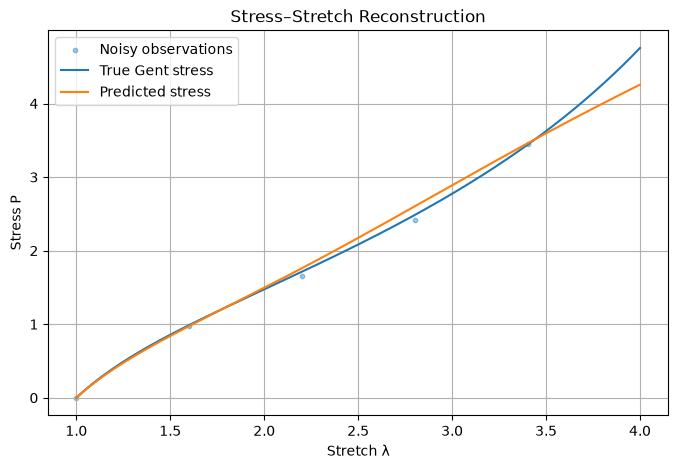

In [409]:
lamda_plot = torch.linspace(1.0, 4.0, 10000)

P_true_plot = gent_stress_function(
    lamda_plot,
    mu,
    jm
)

P_pred_plot = predict_stress(
    model,
    lamda_plot,
    num_samples=50
)

lamda_train = x[:, 0]
Y_train = x[:, 2]


plt.figure(figsize=(8, 5))

plt.scatter(
    lamda_train[::100],
    Y_train[::100],
    s=10,
    alpha=0.4,
    label="Noisy observations"
)

plt.plot(
    lamda_plot,
    P_true_plot,
    label="True Gent stress"
)

plt.plot(
    lamda_plot,
    P_pred_plot,
    label="Predicted stress"
)

plt.xlabel("Stretch λ")
plt.ylabel("Stress P")
plt.title("Stress–Stretch Reconstruction")
plt.legend()
plt.grid()

plt.show()

In [410]:
def predict_energy(model, I1, num_gate_samples=50):

    predictions = []

    for _ in range(num_gate_samples):

        psi_pred = model(I1)

        predictions.append(
            psi_pred.detach()
        )

    psi_pred_mean = torch.stack(
        predictions
    ).mean(dim=0)

    return psi_pred_mean

In [411]:
lamda_plot = torch.linspace(1.0, 4.0, 10000)

I1_plot = (
    lamda_plot**2
    + 2/lamda_plot
).reshape(-1, 1)

psi_true = gent_energy_function(
    I1_plot,
    mu,
    jm
)

psi_pred = predict_energy(
    model,
    I1_plot,
    num_gate_samples=50
)

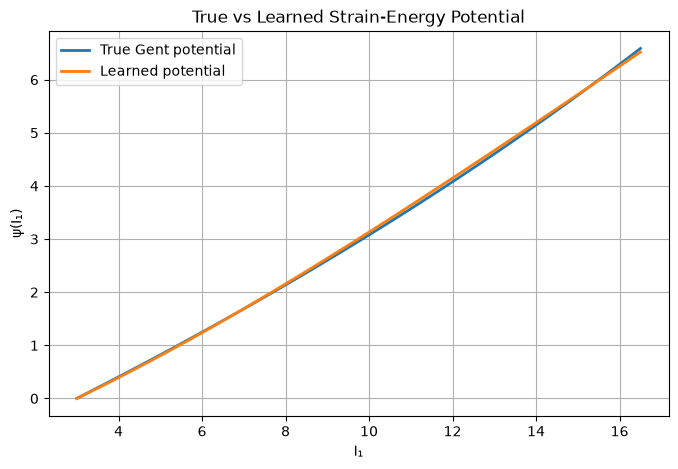

In [412]:
plt.figure(figsize=(8, 5))

plt.plot(
    I1_plot,
    psi_true,
    label="True Gent potential",
    linewidth=2
)

plt.plot(
    I1_plot,
    psi_pred,
    label="Learned potential",
    linewidth=2
)

plt.xlabel("I₁")
plt.ylabel("ψ(I₁)")
plt.title("True vs Learned Strain-Energy Potential")

plt.legend()
plt.grid()

plt.show()

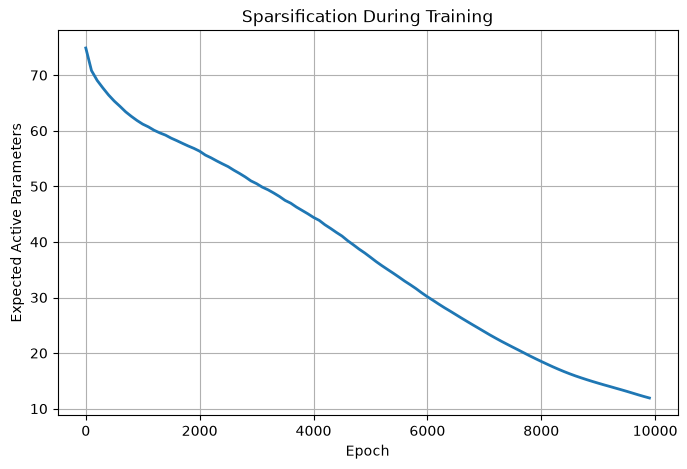

In [413]:
plt.figure(figsize=(8, 5))

plt.plot(
    epoch_history,
    active_history,
    linewidth=2
)

plt.xlabel("Epoch")
plt.ylabel("Expected Active Parameters")
plt.title("Sparsification During Training")

plt.grid()
plt.show()

In [414]:
# Noiseless Reconstruction Without Sparsification
def weighted_loss_part1(model, data, noise_variance, gamma, zeta, beta, log_alpha_a, log_alpha_c, log_alpha_w, log_alpha_b):
    lamda = data[:,0].reshape(-1,1)
    I1 = data[:,1].reshape(-1,1)
    Y_train = data[:,2].reshape(-1,1)
    I1.requires_grad_(True)

    rho = 0
    
    prob_a = torch.sigmoid(log_alpha_a - beta * torch.log(torch.tensor(-gamma/zeta)))  
    prob_c = torch.sigmoid(log_alpha_c - beta * torch.log(torch.tensor(-gamma/zeta)))  
    prob_w = torch.sigmoid(log_alpha_w - beta * torch.log(torch.tensor(-gamma/zeta)))  
    prob_b = torch.sigmoid(log_alpha_b - beta * torch.log(torch.tensor(-gamma/zeta)))

    sparsity_penalty = rho * (torch.sum(prob_a) + torch.sum(prob_c) + torch.sum(prob_w) + torch.sum(prob_b))

    P_pred = model(I1)
    # Compute the gradient of the predicted energy potential with respect to I1
    dW_dI1 = torch.autograd.grad(P_pred, I1, grad_outputs=torch.ones_like(P_pred), create_graph=True)[0]
    P_pred = 2 * dW_dI1 * (lamda - 1/lamda**2)

    noise_variance = None  # Set noise_variance to None for noiseless reconstruction

    squared_error= (P_pred - Y_train)**2
    if noise_variance is None:
        loss = torch.mean(squared_error)
    else:
        noise_variance = noise_variance.reshape(-1, 1)
        loss = torch.mean(squared_error / noise_variance)

    loss += sparsity_penalty
    return loss,P_pred

In [415]:
def Backpropagation_part1(
    model,
    data,
    noise_variance,
    gamma,
    zeta,
    beta,
    learning_rate,
    num_epochs
):

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate
    )

    epoch_history = []
    loss_history = []
    active_history = []

    for epoch in range(num_epochs):

        optimizer.zero_grad()

        loss, P_pred = weighted_loss_part1(
            model,
            data,
            noise_variance,
            gamma=gamma,
            zeta=zeta,
            beta=beta,
            log_alpha_a=model.log_alpha_a,
            log_alpha_c=model.log_alpha_c,
            log_alpha_w=model.log_alpha_w,
            log_alpha_b=model.log_alpha_b
        )

        loss.backward()

        optimizer.step()

        if epoch % 100 == 0:

            active_parameters = expected_active_parameters(
                model
            )

            epoch_history.append(epoch)
            loss_history.append(loss.item())
            active_history.append(active_parameters)

            print(
                f"Epoch [{epoch}/{num_epochs}], "
                f"Loss: {loss.item():.10f}, "
                f"Expected active: {active_parameters:.2f}"
            )

    return epoch_history, loss_history, active_history

In [416]:
model_part1 = NeuralNetwork(m=32)

epoch_history, loss_history, active_history = Backpropagation_part1(
    model_part1,
    x,
    conditional_noise_variance,
    gamma=-0.1,
    zeta=1.1,
    beta=2/3,
    learning_rate=0.01,
    num_epochs=10000
)

Epoch [0/10000], Loss: 563.6824951172, Expected active: 77.02
Epoch [100/10000], Loss: 85.5813369751, Expected active: 73.79
Epoch [200/10000], Loss: 20.3796348572, Expected active: 72.50
Epoch [300/10000], Loss: 9.3978595734, Expected active: 71.69
Epoch [400/10000], Loss: 57.7617340088, Expected active: 71.08
Epoch [500/10000], Loss: 11.3270740509, Expected active: 70.71
Epoch [600/10000], Loss: 5.0960450172, Expected active: 70.50
Epoch [700/10000], Loss: 0.1951128095, Expected active: 70.31
Epoch [800/10000], Loss: 0.1219099909, Expected active: 70.17
Epoch [900/10000], Loss: 0.6781314015, Expected active: 70.05
Epoch [1000/10000], Loss: 0.0914718732, Expected active: 69.98
Epoch [1100/10000], Loss: 0.1661347896, Expected active: 69.88
Epoch [1200/10000], Loss: 0.1276240498, Expected active: 69.79
Epoch [1300/10000], Loss: 1.4870051146, Expected active: 69.72
Epoch [1400/10000], Loss: 1.8955804110, Expected active: 69.68
Epoch [1500/10000], Loss: 0.3713985980, Expected active: 69.6

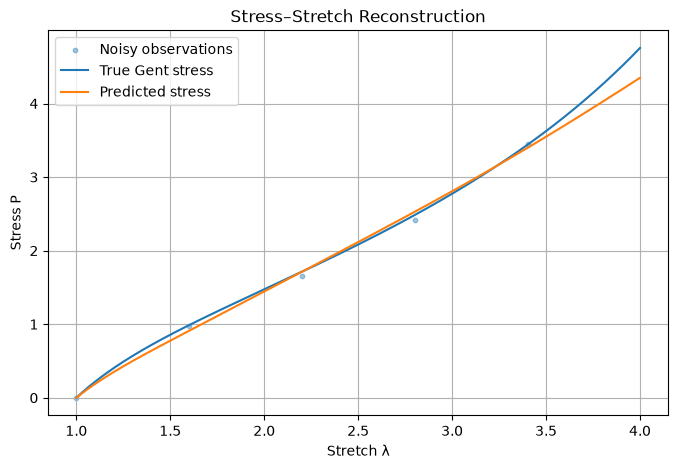

In [417]:
lamda_plot = torch.linspace(1.0, 4.0, 10000)

P_true_plot = gent_stress_function(
    lamda_plot,
    mu,
    jm
)

P_pred_plot = predict_stress(
    model_part1,
    lamda_plot,
    num_samples=50
)

lamda_train = x[:, 0]
Y_train = x[:, 2]


plt.figure(figsize=(8, 5))

plt.scatter(
    lamda_train[::100],
    Y_train[::100],
    s=10,
    alpha=0.4,
    label="Noisy observations"
)

plt.plot(
    lamda_plot,
    P_true_plot,
    label="True Gent stress"
)

plt.plot(
    lamda_plot,
    P_pred_plot,
    label="Predicted stress"
)

plt.xlabel("Stretch λ")
plt.ylabel("Stress P")
plt.title("Stress–Stretch Reconstruction")
plt.legend()
plt.grid()

plt.show()

In [418]:
def predict_energy(model_part1, I1, num_gate_samples=50):

    predictions = []

    for _ in range(num_gate_samples):

        psi_pred = model_part1(I1)

        predictions.append(
            psi_pred.detach()
        )

    psi_pred_mean = torch.stack(
        predictions
    ).mean(dim=0)

    return psi_pred_mean

In [419]:
lamda_plot = torch.linspace(1.0, 4.0, 10000)


I1_plot = (
    lamda_plot**2
    + 2/lamda_plot
).reshape(-1, 1)

psi_true = gent_energy_function(
    I1_plot,
    mu,
    jm
)

psi_pred = predict_energy(
    model_part1,
    I1_plot,
    num_gate_samples=50
)

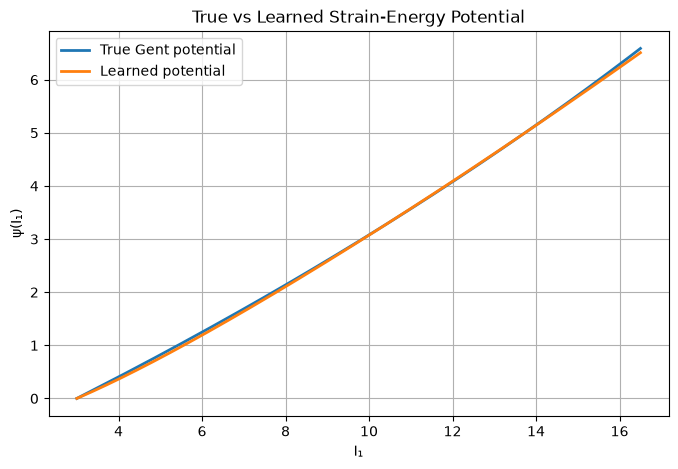

In [420]:
plt.figure(figsize=(8, 5))

plt.plot(
    I1_plot,
    psi_true,
    label="True Gent potential",
    linewidth=2
)

plt.plot(
    I1_plot,
    psi_pred,
    label="Learned potential",
    linewidth=2
)

plt.xlabel("I₁")
plt.ylabel("ψ(I₁)")
plt.title("True vs Learned Strain-Energy Potential")

plt.legend()
plt.grid()

plt.show()

In [421]:
# Noiseless Reconstruction Without Sparsification
def weighted_loss_part2(model,data,noise_variance,gamma,zeta,beta, log_alpha_a, log_alpha_c, log_alpha_w, log_alpha_b):
    lamda = data[:,0].reshape(-1,1)
    I1 = data[:,1].reshape(-1,1)
    Y_train = data[:,2].reshape(-1,1)
    I1.requires_grad_(True)

    rho = 0.35
    
    prob_a = torch.sigmoid(log_alpha_a - beta * torch.log(torch.tensor(-gamma/zeta)))  
    prob_c = torch.sigmoid(log_alpha_c - beta * torch.log(torch.tensor(-gamma/zeta)))  
    prob_w = torch.sigmoid(log_alpha_w - beta * torch.log(torch.tensor(-gamma/zeta)))  
    prob_b = torch.sigmoid(log_alpha_b - beta * torch.log(torch.tensor(-gamma/zeta)))

    sparsity_penalty = rho * (torch.sum(prob_a) + torch.sum(prob_c) + torch.sum(prob_w) + torch.sum(prob_b))

    P_pred = model(I1)
    # Compute the gradient of the predicted energy potential with respect to I1
    dW_dI1 = torch.autograd.grad(P_pred, I1, grad_outputs=torch.ones_like(P_pred), create_graph=True)[0]
    P_pred = 2 * dW_dI1 * (lamda - 1/lamda**2)

    noise_variance = None  # Set noise_variance to None for noiseless reconstruction

    squared_error= (P_pred - Y_train)**2
    if noise_variance is None:
        loss = torch.mean(squared_error)
    else:
        noise_variance = noise_variance.reshape(-1, 1)
        loss = torch.mean(squared_error / noise_variance)

    loss += sparsity_penalty
    return loss,P_pred

In [422]:
def Backpropagation_part2(
    model,
    data,
    noise_variance,
    gamma,
    zeta,
    beta,
    learning_rate,
    num_epochs
):

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate
    )

    epoch_history = []
    loss_history = []
    active_history = []

    for epoch in range(num_epochs):

        optimizer.zero_grad()

        loss, P_pred = weighted_loss_part2(
            model,
            data,
            noise_variance,
            gamma=gamma,
            zeta=zeta,
            beta=beta,
            log_alpha_a=model.log_alpha_a,
            log_alpha_c=model.log_alpha_c,
            log_alpha_w=model.log_alpha_w,
            log_alpha_b=model.log_alpha_b
        )

        loss.backward()

        optimizer.step()

        if epoch % 100 == 0:

            active_parameters = expected_active_parameters(
                model
            )

            epoch_history.append(epoch)
            loss_history.append(loss.item())
            active_history.append(active_parameters)

            print(
                f"Epoch [{epoch}/{num_epochs}], "
                f"Loss: {loss.item():.10f}, "
                f"Expected active: {active_parameters:.2f}"
            )

    return epoch_history, loss_history, active_history

In [423]:
model_part2 = NeuralNetwork(m=32)

epoch_history, loss_history, active_history = Backpropagation_part2(
    model_part2,
    x,
    conditional_noise_variance,
    gamma=-0.1,
    zeta=1.1,
    beta=2/3,
    learning_rate=0.01,
    num_epochs=10000
)

Epoch [0/10000], Loss: 347.3058166504, Expected active: 74.39
Epoch [100/10000], Loss: 42.4326248169, Expected active: 67.46
Epoch [200/10000], Loss: 27.1279773712, Expected active: 61.56
Epoch [300/10000], Loss: 19.8174190521, Expected active: 56.13
Epoch [400/10000], Loss: 19.7901153564, Expected active: 51.61
Epoch [500/10000], Loss: 16.8364639282, Expected active: 47.97
Epoch [600/10000], Loss: 21.1859169006, Expected active: 45.22
Epoch [700/10000], Loss: 17.7669754028, Expected active: 42.97
Epoch [800/10000], Loss: 15.8627748489, Expected active: 41.17
Epoch [900/10000], Loss: 15.6852149963, Expected active: 39.52
Epoch [1000/10000], Loss: 14.8983201981, Expected active: 37.84
Epoch [1100/10000], Loss: 15.6353540421, Expected active: 36.19
Epoch [1200/10000], Loss: 12.9089441299, Expected active: 34.47
Epoch [1300/10000], Loss: 12.4340095520, Expected active: 32.83
Epoch [1400/10000], Loss: 11.0469655991, Expected active: 31.27
Epoch [1500/10000], Loss: 10.4428586960, Expected a

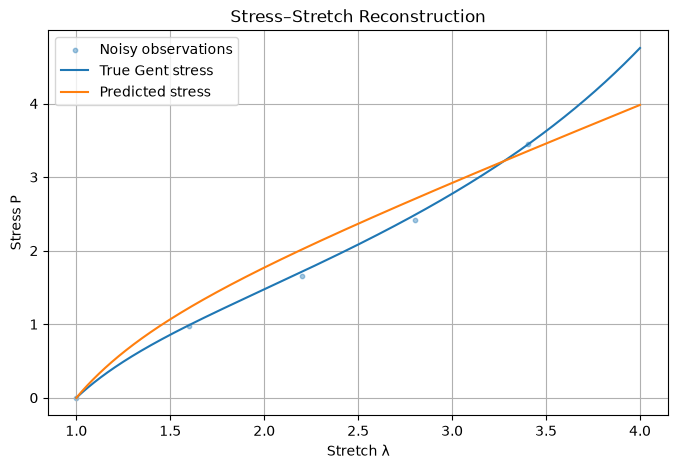

In [424]:
lamda_plot = torch.linspace(1.0, 4.0, 10000)

P_true_plot = gent_stress_function(
    lamda_plot,
    mu,
    jm
)

P_pred_plot = predict_stress(
    model_part2,
    lamda_plot,
    num_samples=50
)

lamda_train = x[:, 0]
Y_train = x[:, 2]


plt.figure(figsize=(8, 5))

plt.scatter(
    lamda_train[::100],
    Y_train[::100],
    s=10,
    alpha=0.4,
    label="Noisy observations"
)

plt.plot(
    lamda_plot,
    P_true_plot,
    label="True Gent stress"
)

plt.plot(
    lamda_plot,
    P_pred_plot,
    label="Predicted stress"
)

plt.xlabel("Stretch λ")
plt.ylabel("Stress P")
plt.title("Stress–Stretch Reconstruction")
plt.legend()
plt.grid()

plt.show()

In [425]:
def predict_energy(model_part2, I1, num_gate_samples=10000):

    predictions = []

    for _ in range(num_gate_samples):

        psi_pred = model_part2(I1)

        predictions.append(
            psi_pred.detach()
        )

    psi_pred_mean = torch.stack(
        predictions
    ).mean(dim=0)

    return psi_pred_mean

In [426]:
lamda_plot = torch.linspace(1.0, 4.0, 10000)

I1_plot = (
    lamda_plot**2
    + 2/lamda_plot
).reshape(-1, 1)

psi_true = gent_energy_function(
    I1_plot,
    mu,
    jm
)

psi_pred = predict_energy(
    model_part2,
    I1_plot,
    num_gate_samples=50
)

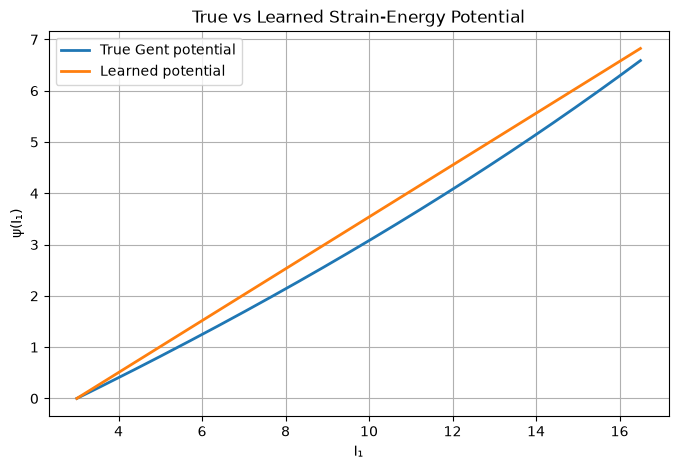

In [427]:
plt.figure(figsize=(8, 5))

plt.plot(
    I1_plot,
    psi_true,
    label="True Gent potential",
    linewidth=2
)

plt.plot(
    I1_plot,
    psi_pred,
    label="Learned potential",
    linewidth=2
)

plt.xlabel("I₁")
plt.ylabel("ψ(I₁)")
plt.title("True vs Learned Strain-Energy Potential")

plt.legend()
plt.grid()

plt.show()

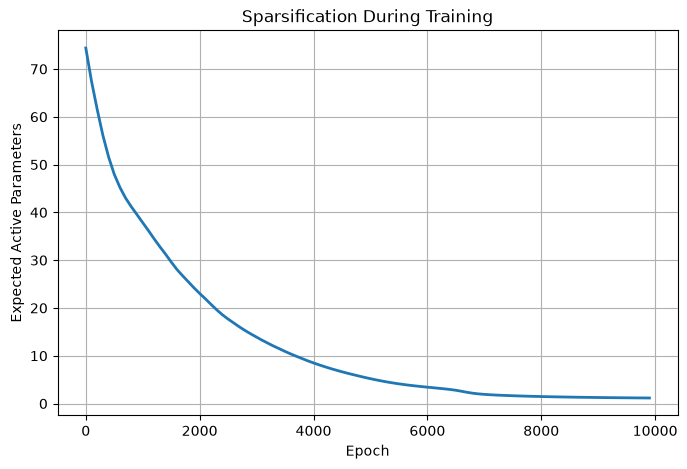

In [428]:
plt.figure(figsize=(8, 5))

plt.plot(
    epoch_history,
    active_history,
    linewidth=2
)

plt.xlabel("Epoch")
plt.ylabel("Expected Active Parameters")
plt.title("Sparsification During Training")

plt.grid()
plt.show()

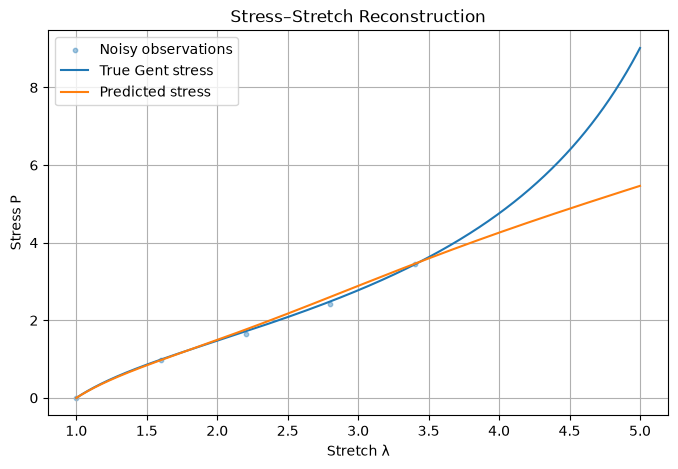

In [ ]:
# Train the model on λ∈[1,4] and evaluate it both on the training range and on an extrapolation interval, for instance λ∈(4,5]

lamda_plot = torch.linspace(1.0, 5.0, 10000)

P_true_plot = gent_stress_function(
    lamda_plot,
    mu,
    jm
)

P_pred_plot = predict_stress(
    model,
    lamda_plot,
    num_samples=10000
)

lamda_train = x[:, 0]
Y_train = x[:, 2]


plt.figure(figsize=(8, 5))

plt.scatter(
    lamda_train[::100],
    Y_train[::100],
    s=10,
    alpha=0.4,
    label="Noisy observations"
)

plt.plot(
    lamda_plot,
    P_true_plot,
    label="True Gent stress"
)

plt.plot(
    lamda_plot,
    P_pred_plot,
    label="Predicted stress"
)

plt.xlabel("Stretch λ")
plt.ylabel("Stress P")
plt.title("Stress–Stretch Reconstruction")
plt.legend()
plt.grid()

plt.show()

In [430]:
# This section outlines an experiment designed to test whether introducing more observational noise into the training data changes how aggressively the neural network deletes its own parameters.

# Here is the exact breakdown of how the experiment is structured and what it aims to evaluate:

# The Experimental Setup
# Controlled Noise Levels: The model is tested under three distinct heteroscedastic noise regimes (low, moderate, and high) to see how varying intensities of data corruption affect the learning process.
# Fixed Variables: The sparsification penalty (rho) and the total training duration or epochsare held completely constant. This ensures that any changes in the final network structure are caused strictly by the noise, not by the training time or the penalty strength.
# Statistical Repetition: To ensure the results are reliable, each noise level is tested multiple times using independent noise patterns and different random starting weights for the neural network.

# The Three Metrics Tracked
# For each training run, the researchers record three specific values to evaluate performance:

#(Sparsity Count): The final count of active, non-zero parameters remaining in the network after the stochastic gates have finished training.
#(Stress Error):The mathematical error in the network's ability to predict the physical stress.
#(Energy Error): The mathematical error in the network's reconstruction of the underlying strain-energy potential.

# The Ultimate Goal
# By mapping the final active parameter count ($S$) against the predictive errors, the experiment seeks to answer two precise questions:

# 1.Aggressive Pruning: Does heavy data noise force the model to systematically hunt down and remove weakly supported parameters more aggressively than it would in clean, low-noise conditions?
# 2.The Core Trade-Off: How does this noise-driven parameter deletion impact the fundamental balance between achieving a highly sparse, interpretable model and maintaining accurate physical predictions?